<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_24_vol1_orange.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 이진분류 - 오렌지 vs 그레이프후루츠

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import random
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)

#데이터 준비

## 데이터 준비

In [3]:
!wget https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/citrus.csv

--2025-12-24 00:26:07--  https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/citrus.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 308294 (301K) [text/plain]
Saving to: ‘citrus.csv’

citrus.csv          100%[===================>] 301.07K  --.-KB/s    in 0.01s   

2025-12-24 00:26:07 (23.4 MB/s) - ‘citrus.csv’ saved [308294/308294]



In [4]:
df = pd.read_csv('/content/citrus.csv')
df.shape

(10000, 6)

In [8]:
df.head()

,name,diameter,weight,red,green,blue
0,orange,2.96,86.76,172,85,2
1,orange,3.91,88.05,166,78,3
2,orange,4.42,95.17,156,81,2
3,orange,4.47,95.60,163,81,4
4,orange,4.48,95.76,161,72,9


##EDA

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      10000 non-null  object 
 1   diameter  10000 non-null  float64
 2   weight    10000 non-null  float64
 3   red       10000 non-null  int64  
 4   green     10000 non-null  int64  
 5   blue      10000 non-null  int64  
dtypes: float64(2), int64(3), object(1)
memory usage: 468.9+ KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diameter,10000.0,9.975685,1.947844,2.96,8.46,9.980,11.4800,16.45
weight,10000.0,175.050792,29.212119,86.76,152.22,174.985,197.7225,261.51
red,10000.0,153.847800,10.432954,115.00,147.00,154.000,161.0000,192.00
green,10000.0,76.010600,11.708433,31.00,68.00,76.000,84.0000,116.00
blue,10000.0,11.363200,9.061275,2.00,2.00,10.000,17.0000,56.00


## 타깃값

In [11]:
df['name'].value_counts()

,count
name,
orange,5000
grapefruit,5000


##결측치

In [12]:
df.isna().sum()

,0
name,0
diameter,0
weight,0
red,0
green,0
blue,0


In [13]:
df.head()

,name,diameter,weight,red,green,blue
0,orange,2.96,86.76,172,85,2
1,orange,3.91,88.05,166,78,3
2,orange,4.42,95.17,156,81,2
3,orange,4.47,95.60,163,81,4
4,orange,4.48,95.76,161,72,9


In [14]:
orange_df = df[df['name']=="orange"]
orange_df.shape

(5000, 6)

In [17]:
grapefruit_df = df[df['name']=="grapefruit"]
grapefruit_df.shape

(5000, 6)

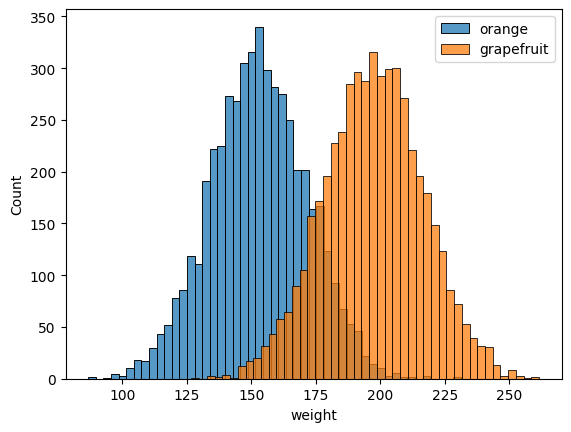

In [22]:
sns.histplot(data=orange_df,x="weight",label="orange")
sns.histplot(data=grapefruit_df,x="weight",label="grapefruit")
plt.legend()
plt.show()

##데이터 분리

In [23]:
from sys import thread_info
from sklearn.model_selection import train_test_split

train,test = train_test_split(df, test_size=0.2, shuffle=True, random_state=SEED)
train.shape, test.shape

((8000, 6), (2000, 6))

In [24]:
train, val = train_test_split(train,test_size=0.2,shuffle=True,random_state=SEED)
train.shape, val.shape

((6400, 6), (1600, 6))

In [25]:
x_train = train.drop('name',axis = 1)
x_val = val.drop('name',axis = 1)

y_train = train['name']
y_val = val['name']

In [26]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((6400, 5), (1600, 5), (6400,), (1600,))

## 데이터 전처리

##인코딩

In [28]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(y_train)

y_train_e = le.transform(y_train)
y_train_e

array([1, 0, 1, ..., 0, 0, 0])

In [29]:
le.classes_

array(['grapefruit', 'orange'], dtype=object)

In [30]:
y_val_e = le.transform(y_val)
y_val_e

array([1, 0, 1, ..., 0, 0, 0])

## 스케일링
- StandardScaler
- MinMaxScaler
- RobustScaler

In [31]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(x_train)

x_train_s = ss.transform(x_train)
x_train_s

array([[-0.7488, -0.7497,  0.1164,  0.6073,  0.2983],
       [ 0.6388,  0.643 , -0.3611,  1.5478,  1.7425],
       [-0.1969, -0.1757, -0.8386,  0.2653, -0.9236],
       ...,
       [-0.233 , -0.308 ,  0.976 ,  0.4363,  2.7423],
       [ 1.7221,  1.7419, -0.0746,  1.0348, -0.8125],
       [ 0.2829,  0.245 , -0.2656, -1.7869,  2.409 ]])

In [33]:
x_val_s = ss.transform(x_val)
x_val_s

array([[-0.5528, -0.541 ,  0.594 ,  1.2058, -1.0347],
       [ 1.0308,  1.0386,  1.9311, -0.1623, -0.7014],
       [-1.0325, -1.0271,  0.3075, -0.5043,  0.2983],
       ...,
       [ 1.7943,  1.8299,  0.3075,  1.2913, -0.3682],
       [ 0.5098,  0.498 , -0.5521, -0.2478,  1.7425],
       [ 0.7935,  0.8049,  1.2625, -0.2478,  1.4092]])

## 최종 학습 데이터

In [35]:
type(x_train_s), type(x_val_s), type(y_train_e), type(y_val_e)

(numpy.ndarray, numpy.ndarray, numpy.ndarray, numpy.ndarray)

In [37]:
x_train_s.shape, x_val_s.shape, y_train_e.shape, y_val_e.shape

((6400, 5), (1600, 5), (6400,), (1600,))

## 베이스라인 모델

In [38]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(x_train_s,y_train_e)

KNeighborsClassifier()

## 평가

In [39]:
y_predict = knn.predict(x_val_s)

In [41]:
y_predict[:20], y_val_e[:20]

(array([1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0]),
 array([1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0]))

In [44]:
(y_predict == y_val_e).sum()/len(y_predict)

np.float64(0.920625)

In [67]:
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"정확도 {acc}")
    print(f"정밀도 {pre}")
    print(f"재현율 {recall}")
    print(f"f1 {f1}")

    cfm = confusion_matrix(y_true,y_pred)

    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.show()

In [46]:
print_metrics(y_val_e,y_predict)

정확도 0.920625
정밀도 0.9181141439205955
재현율 0.9238451935081149
f1 0.9209707529558183


## Confusion Matrix

In [47]:
from sklearn.metrics import confusion_matrix

cfm = confusion_matrix(y_val_e,y_predict)
cfm

array([[733,  66],
       [ 61, 740]])

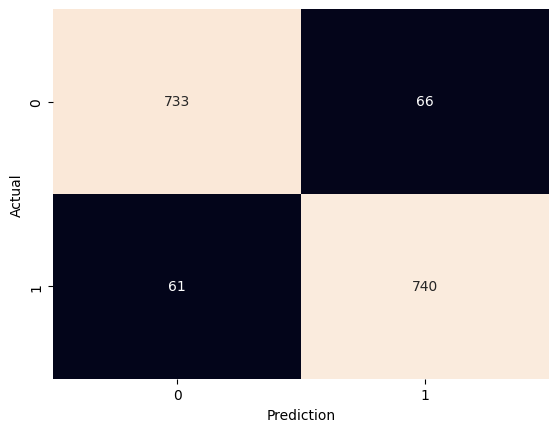

In [51]:
s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
s.set( xlabel='Prediction',ylabel='Actual')
plt.show()

## 모델 튜닝

In [52]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [3,5,7,9,10,12,14], "weights":["uniform","distance"],
    "p":[1,2]
}

In [54]:
grid_search = GridSearchCV(
    KNeighborsClassifier(), param_grid, cv = 5, scoring="accuracy", refit= True, verbose = 1, n_jobs = -1
)

In [56]:
grid_search.fit(x_train_s,y_train_e)

Fitting 5 folds for each of 28 candidates, totalling 140 fits


GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 5, 7, 9, 10, 12, 14], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

In [57]:
grid_search.best_params_

{'n_neighbors': 14, 'p': 1, 'weights': 'uniform'}

In [59]:
grid_search.best_score_

np.float64(0.9228125)

In [60]:
best_model = grid_search.best_estimator_
best_model

KNeighborsClassifier(n_neighbors=14, p=1)

# 테스트

In [63]:
x_test = test.drop('name',axis = 1)
y_test = test['name']

In [64]:
x_test_s = ss.transform(x_test)
y_test_e = le.transform(y_test)

In [65]:
y_test_pred = best_model.predict(x_test_s)

정확도 0.924
정밀도 0.93
재현율 0.9189723320158103
f1 0.9244532803180915


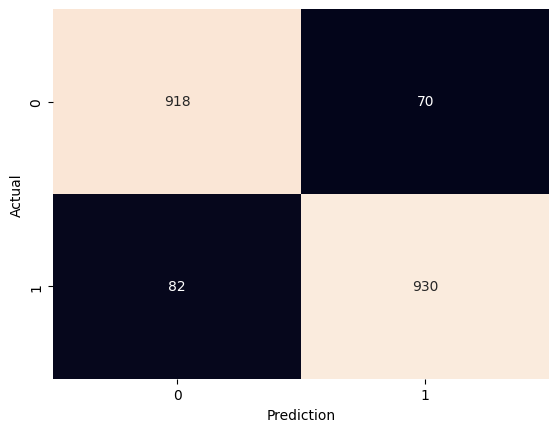

In [68]:
print_metrics(y_test_e,y_test_pred)